In [1]:
from greenbowl_mc import (load_my_criterion, load_my_log,
                          reference_welch, arpu_sample, BASELINE, ALPHA)
import numpy as np
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportion_confint
import matplotlib.pyplot as plt
import matplotlib_inline
import seaborn as sns
import pandas as pd

In [2]:

STUDENT_ID = "ozhelezniakov@kse.org.ua"   
team_criterion = load_my_criterion(STUDENT_ID)
log = load_my_log(STUDENT_ID)

# both criteria share the same call signature:
#   crit(test, control, alternative="two-sided") -> p_value
demo_test    = arpu_sample(260, 200)
demo_control = arpu_sample(250, 200)
print(f"team   : {team_criterion(demo_test, demo_control, "greater"):.4f}")
print(f"welch  : {reference_welch(demo_test, demo_control, 'greater'):.4f}")
print(f"baseline = {BASELINE}, alpha = {ALPHA}")
print(f"Mean test = {np.mean(demo_test):.2f}")
print(f"Mean control = {np.mean(demo_control):.2f}")

team   : 0.7274
welch  : 0.7273
baseline = 250.0, alpha = 0.05
Mean test = 258.88
Mean control = 269.22


* Перевіряємо результат reference_welch за допомогою вбудованої функції (ttest_ind).
* Бачим, що результати сходяться. 

In [3]:
t_test_result = ttest_ind(demo_test, demo_control, equal_var=False, alternative="greater")
ci_ttest = t_test_result.confidence_interval(confidence_level=0.95)
print(f"df = {t_test_result.df:.2f}")
print(f"p-value = {t_test_result.pvalue:.2f}")
print(f"t-statistic = {t_test_result.statistic:.2f}")
print(f"Ci: {ci_ttest.low:.2f} -- {ci_ttest.high:.2f}")

df = 381.33
p-value = 0.73
t-statistic = -0.61
Ci: -38.54 -- inf


* Створюємо функцію для перевірки FPR.

In [4]:
def is_list_or_array(obj):

    return isinstance(obj, (list, np.ndarray))


def simulate_rejections(criterion, test_gen, control_gen, n_test, n_control=None,
                        n_exps=10_000, alpha=0.05,
                        alternative="greater", seed=73) -> dict:
    """A universal Monte Carlo validator.

    Counts the share of H0 rejections + a 95% Wilson CI.
      • test_gen ≡ control_gen, equal means  → share = FPR
      • means differ (there is an effect)    → share = power (TPR)
    equal_var=False → Welch (default); True → Student's t-test.
    """
    if n_control is None:
        n_control = n_test

    np.random.seed(seed)
    rej = 0

    if is_list_or_array(n_test):
        if type(n_test) == list:  # noqa: E721
            n_test = np.array(n_test)

        n_simulation = len(n_test)
        rej = np.zeros(n_simulation)
        low = np.zeros(n_simulation)
        high = np.zeros(n_simulation)
        rate = np.zeros(n_simulation)
        
        for i in range(len(n_test)):
            for _ in range(n_exps):
                test = test_gen(n_test[i])
                control = control_gen(n_control[i])
                pvalue  = criterion(test, control, alternative=alternative)
                rej[i] += pvalue < alpha
            rate[i]   = rej[i] / n_exps
            low[i], high[i] = proportion_confint(rej[i], n_exps, alpha=alpha, method="wilson")
            
    
    else:
        for _ in range(n_exps):
            test    = test_gen(n_test)
            control = control_gen(n_control)
            pvalue  = criterion(test, control, alternative=alternative)
            rej += pvalue < alpha
        rate   = rej / n_exps
        low, high = proportion_confint(rej, n_exps, alpha=alpha, method="wilson")

    return {"rate": rate, "ci_low": low, "ci_high": high}

def test(n):
    return arpu_sample(250, n)   
def control(n):
    return arpu_sample(250, n) 


## Перевірка t-тестом.

In [5]:
n = 400
result = simulate_rejections(reference_welch, test, control, n)
print(f"Sample size: {n}", "\t", f"Times repeat: {10_000}")
print(f"Emperical FPR: {result["rate"]}")
print(f"CI for FPR: {result["ci_low"]:.5f} -- {result["ci_high"]:.5f}")

Sample size: 400 	 Times repeat: 10000
Emperical FPR: 0.0475
CI for FPR: 0.04350 -- 0.05185


## Перевіряємо team_criterion за допомогою A/A тестів.



In [6]:
n = 200
result = simulate_rejections(team_criterion, test, control, n)
print(f"Sample size: {n}", "\t", f"Times repeat: {10_000}")
print(f"Emperical FPR: {result["rate"]}")
print(f"CI for FPR: {result["ci_low"]:.5f} -- {result["ci_high"]:.5f}")


Sample size: 200 	 Times repeat: 10000
Emperical FPR: 0.0497
CI for FPR: 0.04561 -- 0.05414


In [7]:
n = 400
result = simulate_rejections(team_criterion, test, control, n)
print(f"Sample size: {n}", "\t", f"Times repeat: {10_000}")
print(f"Emperical FPR: {result["rate"]}")
print(f"CI for FPR: {result["ci_low"]:.5f} -- {result["ci_high"]:.5f}")

Sample size: 400 	 Times repeat: 10000
Emperical FPR: 0.0475
CI for FPR: 0.04350 -- 0.05185


In [8]:
n = 600
result = simulate_rejections(team_criterion, test, control, n)
print(f"Sample size: {n}", "\t", f"Times repeat: {10_000}")
print(f"Emperical FPR: {result["rate"]}")
print(f"CI for FPR: {result["ci_low"]:.5f} -- {result["ci_high"]:.5f}")

Sample size: 600 	 Times repeat: 10000
Emperical FPR: 0.0516
CI for FPR: 0.04743 -- 0.05611


* Перевіряємо на вибірці 800 (n = 800)

In [9]:
n = 800
gen_group = lambda n: arpu_sample(250, n, sigma=0.6)  # noqa: E731
result = simulate_rejections(team_criterion, gen_group, gen_group, n)
print(f"Sample size: {n}", "\t", f"Times repeat: {10_000}")
print(f"Emperical FPR: {result["rate"]}")
print(f"CI for FPR: {result["ci_low"]:.5f} -- {result["ci_high"]:.5f}")

Sample size: 800 	 Times repeat: 10000
Emperical FPR: 0.0493
CI for FPR: 0.04523 -- 0.05372


* Перевіряємо на маленьких вибірка та виводимо повну таблицю

In [10]:
n_values = np.array([5, 10, 20, 50, 100, 200, 400, 600, 800])
gen_group = lambda n: arpu_sample(250, n, sigma=0.6)  # noqa: E731
result = simulate_rejections(team_criterion, gen_group, gen_group, n_values)
result_df800 = pd.DataFrame(result)
result_df800["n"] = n_values
result_df800["Is correct?"] = (result_df800["ci_low"] <= 0.05) & (0.05 <= result_df800 ["ci_high"])
result_df800["Is correct?"] = np.where(result_df800["Is correct?"], "✅", "⛔")
result_df800[["n", "rate", "ci_low", "ci_high", "Is correct?"]].rename(columns={"ci_low": "CI low", "ci_high": "CI high", "rate": "FPR"})

,n,FPR,CI low,CI high,Is correct?
0,5,0.0636,0.058982,0.068553,⛔
1,10,0.0555,0.051181,0.060160,⛔
2,20,0.0497,0.045611,0.054135,✅
3,50,0.0513,0.047146,0.055799,✅
4,100,0.0517,0.047530,0.056214,✅
5,200,0.0502,0.046090,0.054655,✅
6,400,0.0532,0.048970,0.057773,✅
7,600,0.0522,0.048010,0.056734,✅
8,800,0.0519,0.047722,0.056422,✅


## Шукаємо мінімальне n для якого емпіричне FPR буде в CI

* Створюємо функцію min_sample_size для Power = 0.8 мінімального n

* Виводимо таблицю з результатами для тих n, які нас цікавлять 

In [11]:
def min_sample_size(criterion, test_gen, control_gen, grid,
                        n_exps=10_000, alpha=0.05, 
                        alternative="greater", seed=73) -> int:

    np.random.seed(seed)

    if type(grid) == list:  # noqa: E721
            grid = np.array(control_gen)

    n_simulation = len(grid)
    rej = np.zeros(n_simulation)
    low = np.zeros(n_simulation)
    high = np.zeros(n_simulation)
    rate = np.zeros(n_simulation)
    
    for i in range(n_simulation):
        for _ in range(n_exps):
            test = test_gen(grid[i])
            control = control_gen(grid[i])
            pvalue  = criterion(test, control, alternative=alternative)
            rej[i] += pvalue < alpha
        low[i], high[i] = proportion_confint(rej[i], n_exps, alpha=alpha, method="wilson")
        rate[i]   = rej[i] / n_exps

    grid = grid[(low <= 0.05) & (0.05 <= high)]
    return np.min(grid)



In [12]:
grid = np.arange(11, 20)
result = min_sample_size(team_criterion, gen_group, gen_group, grid)
print(f"Min n for FPR in CI: {result}")

Min n for FPR in CI: 13


In [13]:
grid = np.arange(11, 20)
gen_group = lambda n: arpu_sample(250, n, sigma=0.6)  # noqa: E731
result = simulate_rejections(team_criterion, gen_group, gen_group, grid)
result_df = pd.DataFrame(result)
result_df["n"] = grid
result_df["Is correct"] = (result_df["ci_low"] <= 0.05) & (0.05 <= result_df ["ci_high"])
result_df["Is correct"] = np.where(result_df["Is correct"], "✅", "⛔")
result_df[["n", "rate", "ci_low", "ci_high", "Is correct"]].rename(columns={"ci_low": "CI low", "ci_high": "CI high", "rate": "FPR"})

,n,FPR,CI low,CI high,Is correct
0,11,0.0553,0.050989,0.059953,⛔
1,12,0.0566,0.052239,0.061302,⛔
2,13,0.0541,0.049835,0.058707,✅
3,14,0.0519,0.047722,0.056422,✅
4,15,0.0516,0.047434,0.056111,✅
5,16,0.0548,0.050508,0.059434,⛔
6,17,0.0497,0.045611,0.054135,✅
7,18,0.0531,0.048874,0.057669,✅
8,19,0.0521,0.047914,0.056630,✅


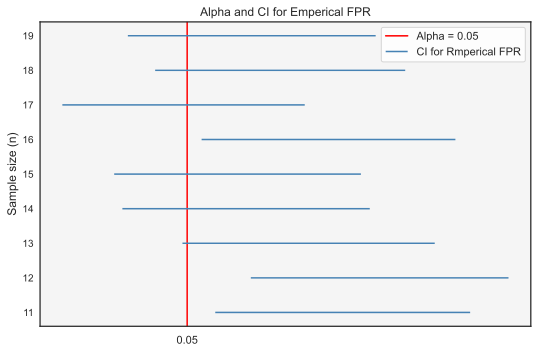

In [14]:
matplotlib_inline.backend_inline.set_matplotlib_formats("svg")
sns.set_theme(style="white")
result_df["y_cords"] = grid

fig, ax = plt.subplots(figsize=(8 * 1.1, 5 * 1.1))

ax.axvline(0.05, color="red", label="Alpha = 0.05")
ax.hlines(y=result_df['n'], 
          xmin=result_df['ci_low'], 
          xmax=result_df['ci_high'], 
          color="steelblue", label="CI for Rmperical FPR")

ax.set_title("Alpha and CI for Emperical FPR")
ax.set_xticks(np.array([0.05]))
ax.set_yticks(result_df['n'])
ax.set_facecolor("#F5F5F5")
ax.set_ylabel("Sample size (n)")
ax.tick_params(
    axis='y',       
    which='major',     
    labelsize=10,       
    length=3,         
    width=0.8          
)

plt.show()

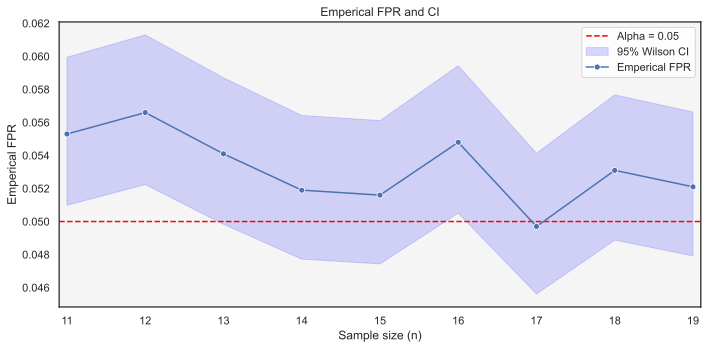

In [15]:
sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(10, 5))

ax.axhline(0.05, color="red", linestyle="--", label="Alpha = 0.05")
ax.fill_between(result_df["y_cords"], result_df["ci_low"], result_df["ci_high"], color="blue", alpha=0.15, label="95% Wilson CI")
sns.lineplot(data=result_df, x="y_cords", y="rate", label="Emperical FPR", marker="o")
 

ax.set_facecolor("#F5F5F5")
ax.set_xlim(11 - 0.1, 19 + 0.1)
ax.set_xticks(grid)
ax.set_xlabel("Sample size (n)")
ax.set_ylabel("Emperical FPR")
ax.set_title("Emperical FPR and CI")

plt.legend()
plt.tight_layout()
plt.show()

In [16]:
def emperical_power(mde_grid, mean=250, sample_size=400, n_exps=10_000):
    n = sample_size  # noqa: F841

    n_simulation = len(mde_grid)
    rate = np.zeros(n_simulation)
    low = np.zeros(n_simulation)
    high = np.zeros(n_simulation)
    
    for i in range(len(mde_grid)):  
        gen_group_1 = lambda n: arpu_sample(mean + mde_grid[i], n, sigma=0.6)  # noqa: E731, F841
        gen_group_2 = lambda n: arpu_sample(mean, n, sigma=0.6)  # noqa: E731
        
        result = simulate_rejections(team_criterion, gen_group_1, gen_group_2, n, n_exps=n_exps)

        rate[i] += result["rate"]
        low[i] += result["ci_low"]
        high[i] += result["ci_high"]
    
    return {"rate": rate, "ci_low": low, "ci_high": high}



In [17]:
mde_grid =  np.arange(5, 50, 5)
resultmde = emperical_power(mde_grid)
result_dfmde = pd.DataFrame(resultmde)
result_dfmde["MDE"] = mde_grid
result_dfmde["Is_correct"] = np.where(result_dfmde["rate"] >= 0.8, "✅", "⛔") 
result_dfmde[["MDE", "rate", "ci_low", "ci_high", "Is_correct"]].rename(columns={"ci_low": "CI low", "ci_high": "CI high", "rate": "Power", "Is_correct": "Is correct?"})

,MDE,Power,CI low,CI high,Is correct?
0,5,0.1061,0.100215,0.112288,⛔
1,10,0.2109,0.203016,0.219006,⛔
2,15,0.3499,0.340611,0.359304,⛔
3,20,0.5078,0.498000,0.517594,⛔
4,25,0.6613,0.651964,0.670512,⛔
5,30,0.7898,0.781704,0.797674,⛔
6,35,0.8809,0.874405,0.887103,✅
7,40,0.9405,0.935692,0.944969,✅
8,45,0.9736,0.970271,0.976565,✅


In [18]:
mde_grid =  np.arange(1, 60, 1)
resultmde = emperical_power(mde_grid)

result_dfmde = pd.DataFrame(resultmde)
result_dfmde["MDE"] = mde_grid 
result_dfmde = result_dfmde.rename(columns={"rate": "Power"})

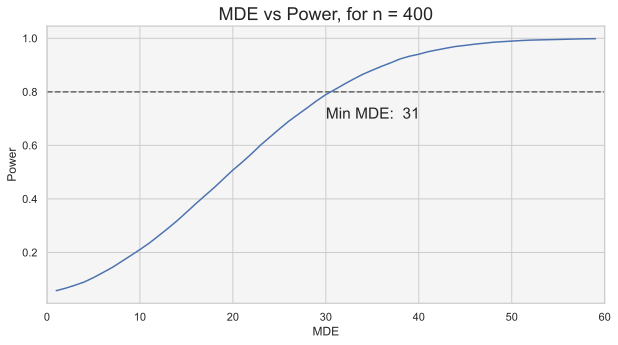

In [19]:
min_mde = result_dfmde.loc[result_dfmde["Power"] >= 0.8, 'MDE'].min()
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

ax.axhline(0.8, color="dimgrey", linestyle="--")
sns.lineplot(data=result_dfmde, x="MDE", y="Power")
ax.text(30, 0.7, f"Min MDE:  {min_mde}", size = 15.5)

ax.set_facecolor("#F5F5F5")
ax.set_xlim(0, 60)
ax.set_title("MDE vs Power, for n = 400", size=18)

#plt.tight_layout()
plt.show()

## ≈1000 A/A тестів на вашому історичному журналі

* Робимо тести та виводимо результати 
* Робимо функуію, яка рахуємо потуєність та виводимо результати

In [20]:
def thousand_aa_tests(log, criterion, alpha=0.05, lift=0.0,
                      alternative="two-sided", seed=1):
    rng, rej, k = np.random.default_rng(seed), 0, 0
    for _, gdf in log.groupby(["city", "cuisine"]):
        arpu = gdf["arpu"].to_numpy()
        idx  = rng.permutation(len(arpu))      # INDEPENDENT split per slice
        half = len(arpu) // 2
        control = arpu[idx[:half]]
        test    = arpu[idx[half:2 * half]] * (1 + lift)   # lift=0 -> A/A
        rej += criterion(test, control, alternative) < alpha
        k   += 1
    low, high = proportion_confint(rej, k, alpha=0.05, method="wilson")
    return {"FPR": [rej / k], "ci_low": [low], "ci_high": [high], "k": [k]}

def thousand_aa_tests_power(lift_grid):
    n_simulation = len(lift_grid)
    low = np.zeros(n_simulation)
    high = np.zeros(n_simulation)
    rate = np.zeros(n_simulation)

    for i in range(len(lift_grid)):
        result_log = thousand_aa_tests(log, team_criterion, lift=lift_grid[i])
        rate[i] = result_log["FPR"][0]
        high[i] = result_log["ci_high"][0]
        low[i] = result_log["ci_low"][0]

    
    return {"lift": np.round(lift_grid, 2), "Power": rate, "ci_low": low, "ci_high": high}

In [21]:
result_log = thousand_aa_tests(log, team_criterion)
result_log_df = pd.DataFrame(result_log)
result_log_df.rename(columns={"ci_low": "CI low", "ci_high": "CI High"}).T.rename(columns={0:"Result"})

,Result
FPR,0.025000
CI low,0.012721
CI High,0.048548
k,320.000000


In [22]:
lift_grid = np.hstack((np.array([0.03, 0.05, 0.07, 0.1, 0.12, 0.15]), np.arange(15, 60, 5) / 100))

result_log_power = thousand_aa_tests_power(lift_grid)
result_log_power_df = pd.DataFrame(result_log_power)
result_log_power_df["Is correct?"] = np.where(result_log_power_df["Power"] >= 0.8, "✅", "⛔") 
result_log_power_df.rename(columns={"ci_low": "CI low", "ci_high": "CI high"})

,lift,Power,CI low,CI high,Is correct?
0,0.03,0.037500,0.021580,0.064393,⛔
1,0.05,0.065625,0.043320,0.098235,⛔
2,0.07,0.121875,0.090449,0.162272,⛔
3,0.10,0.215625,0.174080,0.263916,⛔
4,0.12,0.278125,0.231885,0.329629,⛔
5,0.15,0.359375,0.308758,0.413328,⛔
6,0.15,0.359375,0.308758,0.413328,⛔
7,0.20,0.534375,0.479638,0.588297,⛔
8,0.25,0.725000,0.673626,0.771036,⛔
9,0.30,0.825000,0.779582,0.862708,✅


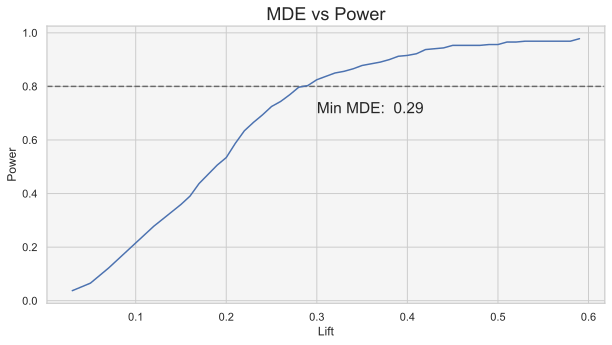

In [23]:
lift_grid = np.hstack((np.array([0.03, 0.05, 0.07, 0.1, 0.12, 0.15]), np.arange(15, 60, 1) / 100))
result_log_power = thousand_aa_tests_power(lift_grid)
result_log_power_df = pd.DataFrame(result_log_power)
min_lift = result_log_power_df.loc[result_log_power_df["Power"] >= 0.8, 'lift'].min()
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

ax.axhline(0.8, color="dimgrey", linestyle="--")
sns.lineplot(data=result_log_power_df, x="lift", y="Power")
ax.text(0.3, 0.7, f"Min MDE:  {min_lift}", size = 15.5)

ax.set_facecolor("#F5F5F5")
ax.set_title("MDE vs Power", size=18)
ax.set_xlabel("Lift")
#plt.tight_layout()
plt.show()

## Робимо групи залежними

* Ми бачимо, що FPR виріс

* Так відбувається, оскільки $H_0$ тепер не правда, тому частіше робимо reject

* Що  дивно FPR став нормальним

In [24]:
def depend_thousand_aa_tests(log, criterion, alpha=0.05, lift=0.0,
                      alternative="two-sided", seed=1):
    rng, rej, k = np.random.default_rng(seed), 0, 0
    for _, gdf in log.groupby(["city", "cuisine"]):
        arpu = gdf["arpu"].to_numpy()
        arpu = np.sort(arpu)
        idx  = rng.permutation(len(arpu))      # INDEPENDENT split per slice
        half = len(arpu) // 2
        control = arpu[idx[:half]]
        test    = arpu[idx[half:2 * half]] * (1 + lift)   # lift=0 -> A/A
        rej += criterion(test, control, alternative) < alpha
        k   += 1
    low, high = proportion_confint(rej, k, alpha=0.05, method="wilson")
    return {"FPR": [rej / k], "ci_low": [low], "ci_high": [high], "k": [k]}

In [25]:
result_log = depend_thousand_aa_tests(log, team_criterion)
result_log_df = pd.DataFrame(result_log)
result_log_df.rename(columns={"ci_low": "CI low", "ci_high": "CI High"}).T.rename(columns={0:"Result"})

,Result
FPR,0.050000
CI low,0.031008
CI High,0.079668
k,320.000000


## Тест валідний, але з обмеженнями

* На реальних даних дуже низький FPR, тому Power теж низький

* Нам треба коипенсувати більшим MDE або N